In [34]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from IPython.display import display
import itertools
from sklearn.model_selection import train_test_split

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


## Sequential Data Formulation & Normalization

In [10]:
class KannadaSeqDataset(Dataset):
    def __init__(self, data_df):
        self.labels = data_df.iloc[:, 0].values

        # Reshape to (N, 28, 28) for 28 timesteps x 28 features
        # Normalize raw pixel intensities to the [0, 1] interval[cite: 1]
        self.images = data_df.iloc[:, 1:].values.reshape(-1, 28, 28).astype(np.float32) / 255.0

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return torch.tensor(self.images[idx]), torch.tensor(self.labels[idx], dtype=torch.long)

In [11]:
# Load raw data
raw_df = pd.read_csv('train.csv')

# Train (70%), Validation (15%), Test (15%) splits
train_df, temp_df = train_test_split(raw_df, test_size=0.30, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42)

train_loader = DataLoader(KannadaSeqDataset(train_df), batch_size=128, shuffle=True)
val_loader = DataLoader(KannadaSeqDataset(val_df), batch_size=128, shuffle=False)
test_loader = DataLoader(KannadaSeqDataset(test_df), batch_size=128, shuffle=False)

print(f"Train size: {len(train_df)} | Val size: {len(val_df)} | Test size: {len(test_df)}")

Train size: 42000 | Val size: 9000 | Test size: 9000


## Unified Recurrent Model Architecture


In [12]:
class RecurrentDigitClassifier(nn.Module):
    def __init__(self, input_size=28, hidden_size=128, num_layers=2, num_classes=10, rnn_type='LSTM'):
        super(RecurrentDigitClassifier, self).__init__()
        self.rnn_type = rnn_type

        if rnn_type == 'RNN':
            self.rnn = nn.RNN(input_size, hidden_size, num_layers, batch_first=True)
        elif rnn_type == 'LSTM':
            self.rnn = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        elif rnn_type == 'GRU':
            self.rnn = nn.GRU(input_size, hidden_size, num_layers, batch_first=True)

        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        out, _ = self.rnn(x)
        return self.fc(out[:, -1, :]) # Extract hidden state from the final time step

## Training Loop with Dynamic Convergence Criteria

In [13]:
def train_and_evaluate_tracked(model, train_loader, learning_rate=0.001):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    prev_train_loss = float('inf')
    epoch = 1
    loss_history = []

    while True:
        model.train()
        running_loss = 0.0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * images.size(0)

        avg_train_loss = running_loss / len(train_loader.dataset)
        loss_history.append(avg_train_loss)

        # Stop training when absolute difference < 10^-4
        if abs(avg_train_loss - prev_train_loss) < 1e-4:
            break

        prev_train_loss = avg_train_loss
        epoch += 1

    return model, loss_history, epoch

In [14]:
def get_accuracy(model, data_loader):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in data_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    return (correct / total) * 100

## Execution & Hyperparameter Tuning

In [15]:
hidden_sizes = [32, 64, 128, 256]
num_layers_list = [1, 2, 3]
rnn_types = ['RNN', 'LSTM', 'GRU']

tuning_results = []
loss_histories = {}
trained_models_dict = {}

for rnn_type, hidden_size, num_layers in itertools.product(rnn_types, hidden_sizes, num_layers_list):
    print(f"Training {rnn_type} | Neurons: {hidden_size} | Layers: {num_layers}...")

    model = RecurrentDigitClassifier(hidden_size=hidden_size, num_layers=num_layers, rnn_type=rnn_type)
    trained_model, loss_history, epochs_run = train_and_evaluate_tracked(model, train_loader)

    train_acc = get_accuracy(trained_model, train_loader)
    test_acc = get_accuracy(trained_model, test_loader)

    config_name = f"{rnn_type}_N{hidden_size}_L{num_layers}"
    loss_histories[config_name] = loss_history
    trained_models_dict[config_name] = trained_model

    tuning_results.append({
        'Model': rnn_type, 'Neurons': hidden_size, 'Layers': num_layers,
        'Epochs': epochs_run, 'Train Acc (%)': round(train_acc, 2), 'Test Acc (%)': round(test_acc, 2)
    })

Training RNN | Neurons: 32 | Layers: 1...
Training RNN | Neurons: 32 | Layers: 2...
Training RNN | Neurons: 32 | Layers: 3...
Training RNN | Neurons: 64 | Layers: 1...
Training RNN | Neurons: 64 | Layers: 2...
Training RNN | Neurons: 64 | Layers: 3...
Training RNN | Neurons: 128 | Layers: 1...
Training RNN | Neurons: 128 | Layers: 2...
Training RNN | Neurons: 128 | Layers: 3...
Training RNN | Neurons: 256 | Layers: 1...
Training RNN | Neurons: 256 | Layers: 2...
Training RNN | Neurons: 256 | Layers: 3...
Training LSTM | Neurons: 32 | Layers: 1...
Training LSTM | Neurons: 32 | Layers: 2...
Training LSTM | Neurons: 32 | Layers: 3...
Training LSTM | Neurons: 64 | Layers: 1...
Training LSTM | Neurons: 64 | Layers: 2...
Training LSTM | Neurons: 64 | Layers: 3...
Training LSTM | Neurons: 128 | Layers: 1...
Training LSTM | Neurons: 128 | Layers: 2...
Training LSTM | Neurons: 128 | Layers: 3...
Training LSTM | Neurons: 256 | Layers: 1...
Training LSTM | Neurons: 256 | Layers: 2...
Training LST

## Summary Table

In [36]:
results_df = pd.DataFrame(tuning_results)
results_df.sort_values(by=['Test Acc (%)'], ascending=False, inplace=True)
display(results_df)

,Model,Neurons,Layers,Epochs,Train Acc (%),Test Acc (%)
35,GRU,256,3,30,99.95,99.39
14,LSTM,32,3,95,100.00,99.38
17,LSTM,64,3,79,100.00,99.34
30,GRU,128,1,61,100.00,99.32
31,GRU,128,2,38,99.99,99.29
20,LSTM,128,3,31,99.93,99.27
19,LSTM,128,2,26,99.80,99.26
29,GRU,64,3,31,99.92,99.18
32,GRU,128,3,19,99.82,99.10
33,GRU,256,1,13,99.65,99.09


## Learning Curve Plots

###  Vanilla RNN Learning Curves

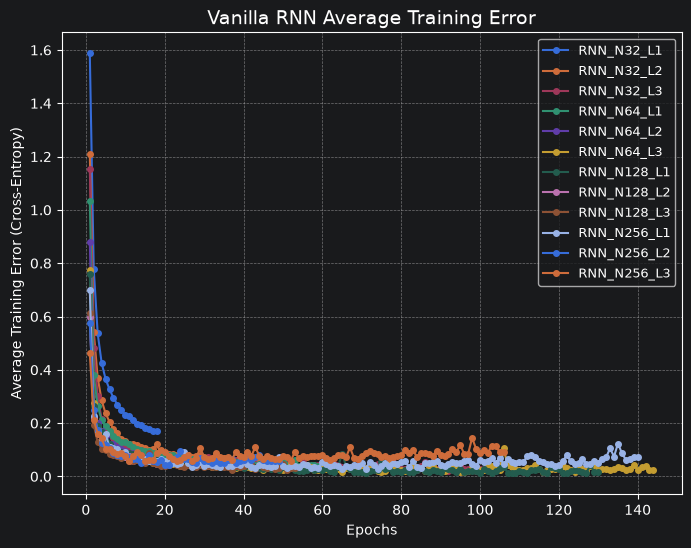

In [24]:
plt.figure(figsize=(8, 6))
for config, history in loss_histories.items():
    if config.startswith('RNN'):
        plt.plot(range(1, len(history) + 1), history, marker='o', markersize=4, label=config)

plt.title('Vanilla RNN Average Training Error', fontsize=14)
plt.xlabel('Epochs')
plt.ylabel('Average Training Error (Cross-Entropy)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9, loc='upper right')
plt.show()

### LSTM Learning Curves

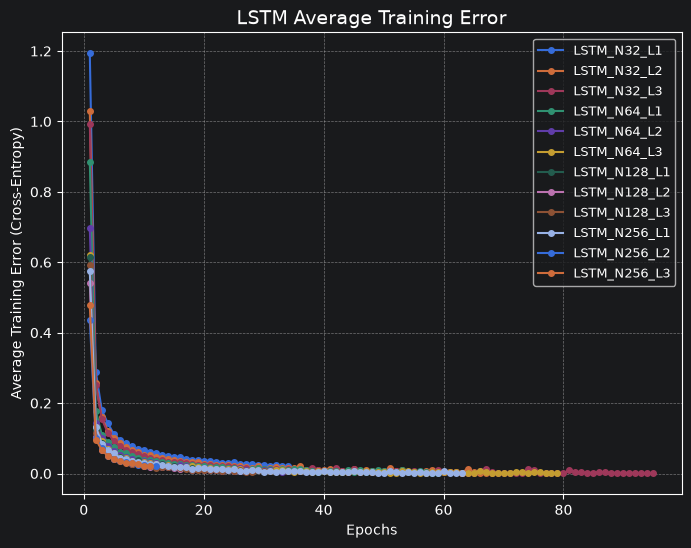

In [25]:
plt.figure(figsize=(8, 6))
for config, history in loss_histories.items():
    if config.startswith('LSTM'):
        plt.plot(range(1, len(history) + 1), history, marker='o', markersize=4, label=config)

plt.title('LSTM Average Training Error', fontsize=14)
plt.xlabel('Epochs')
plt.ylabel('Average Training Error (Cross-Entropy)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9, loc='upper right')
plt.show()

### GRU Learning Curves

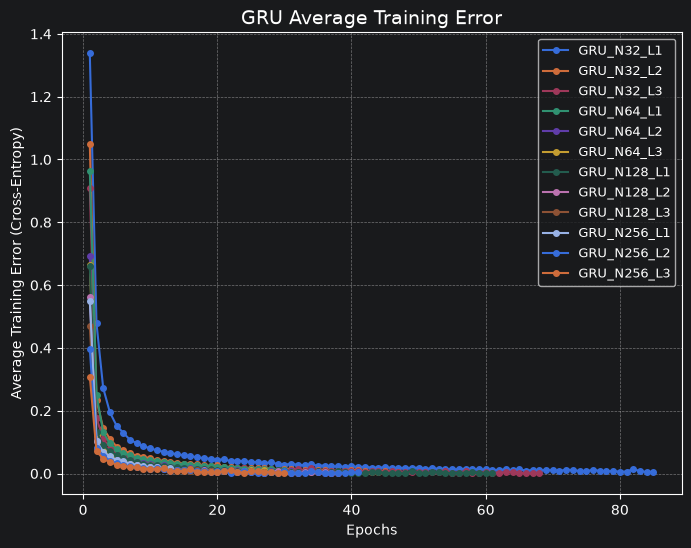

In [26]:
plt.figure(figsize=(8, 6))
for config, history in loss_histories.items():
    if config.startswith('GRU'):
        plt.plot(range(1, len(history) + 1), history, marker='o', markersize=4, label=config)

plt.title('GRU Average Training Error', fontsize=14)
plt.xlabel('Epochs')
plt.ylabel('Average Training Error (Cross-Entropy)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=9, loc='upper right')
plt.show()

## Best Model Summary Table

In [35]:
best_model_summary = results_df.head(1).copy()

print("Best Model Summary Table:")
display(best_model_summary)

Best Model Summary Table:


,Model,Neurons,Layers,Epochs,Train Acc (%),Test Acc (%)
35,GRU,256,3,30,99.95,99.39


## Best Model Complete Confusion Matrix

Best Configuration: GRU_N256_L3


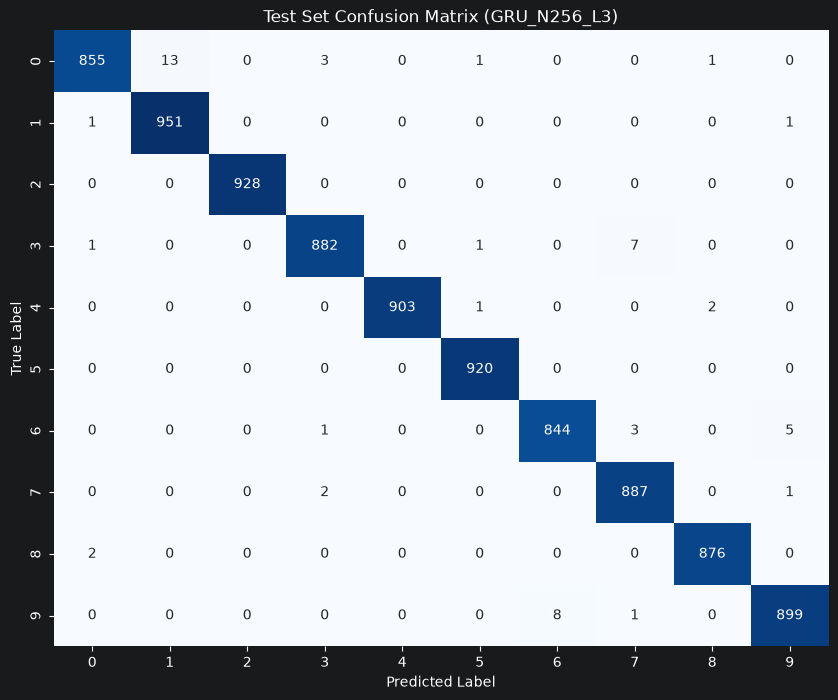

In [31]:
# Automatically select the best configuration based on test accuracy
best_config = results_df.iloc[0]
best_model_name = f"{best_config['Model']}_N{best_config['Neurons']}_L{best_config['Layers']}"
best_model = trained_models_dict[best_model_name]

print(f"Best Configuration: {best_model_name}")

def get_all_preds(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
    return all_labels, all_preds

test_y, test_pred = get_all_preds(best_model, test_loader)
cm = confusion_matrix(test_y, test_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title(f'Test Set Confusion Matrix ({best_model_name})')
plt.show()

## Qualitative Heatmap Visualizations

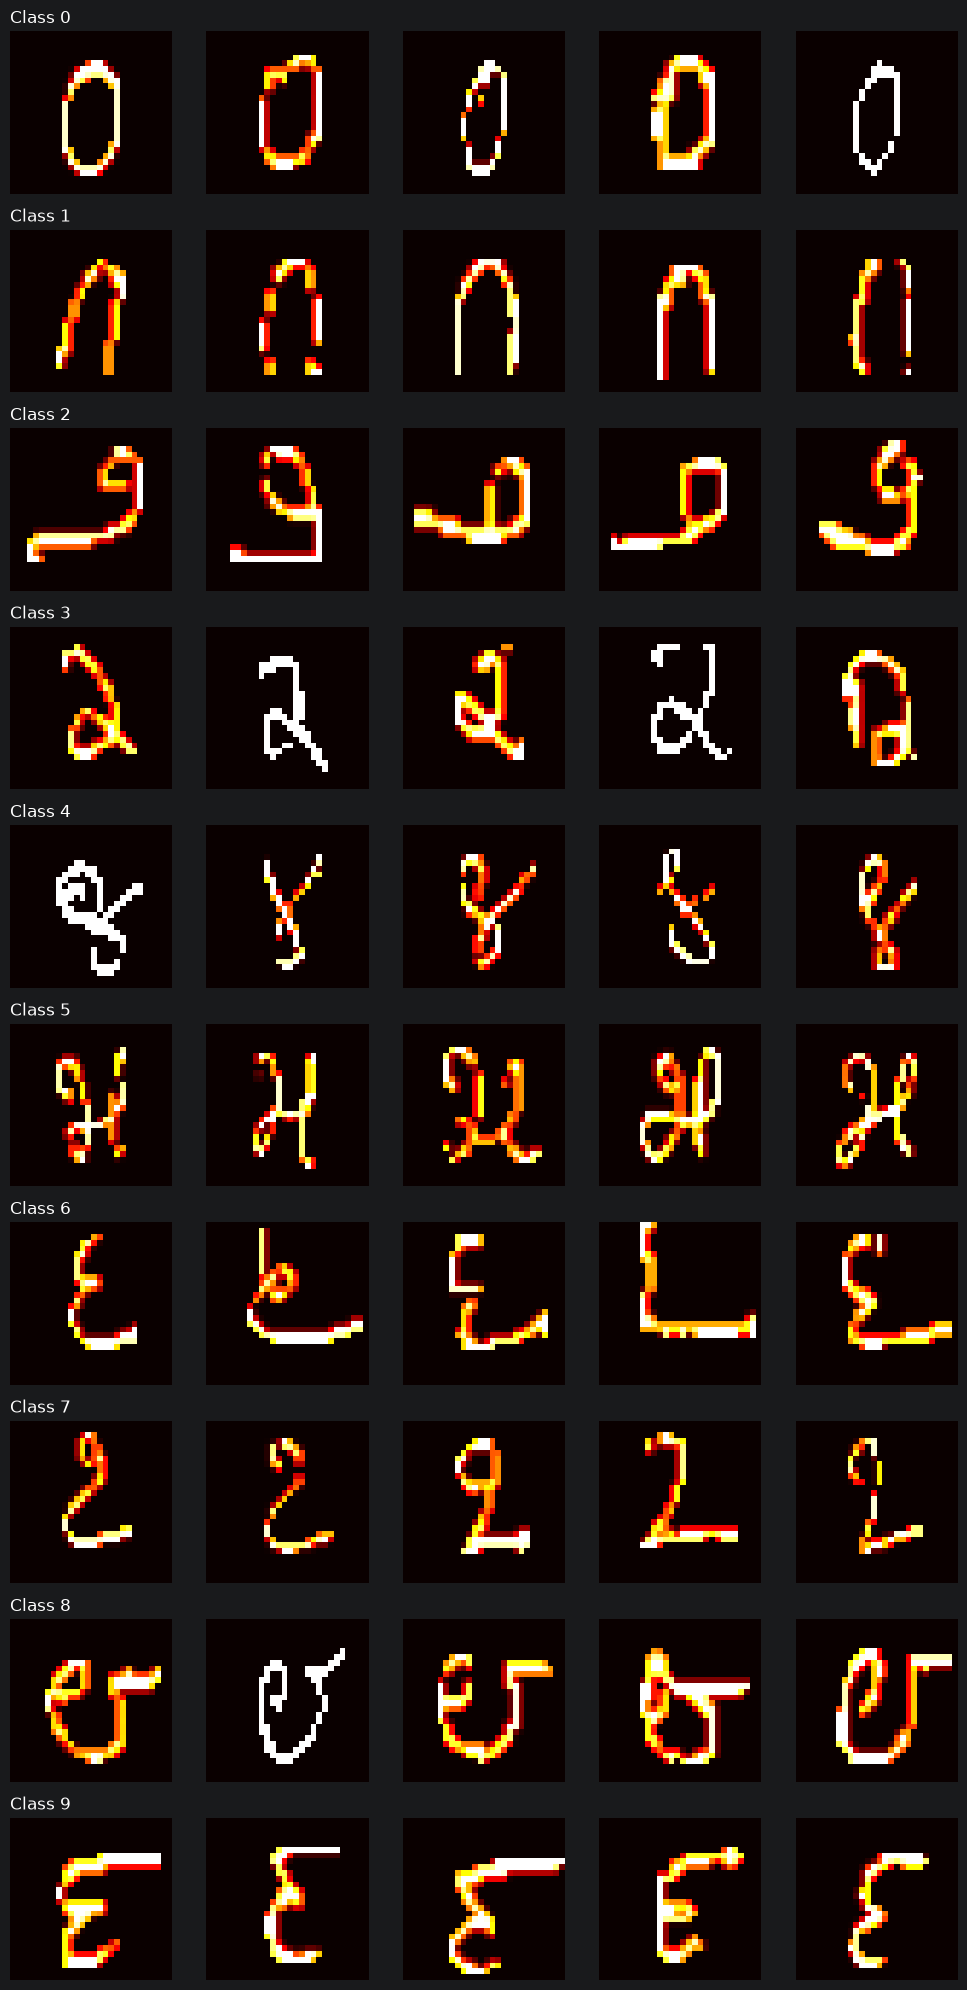

In [28]:
def plot_kannada_heatmaps(dataset, samples_per_class=5, num_classes=10):
    fig, axes = plt.subplots(num_classes, samples_per_class, figsize=(10, 20))
    counts = {i: 0 for i in range(num_classes)}

    for image, label in dataset:
        lbl = label.item()
        if counts[lbl] < samples_per_class:
            ax = axes[lbl, counts[lbl]]
            ax.imshow(image.numpy(), cmap='hot', interpolation='nearest')
            ax.axis('off')

            if counts[lbl] == 0:
                ax.set_title(f"Class {lbl}", loc='left')

            counts[lbl] += 1

        if all(c == samples_per_class for c in counts.values()):
            break

    plt.tight_layout()
    plt.show()

# Pass raw un-shuffled data for visualization
plot_kannada_heatmaps(KannadaSeqDataset(train_df))